In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sqlite3
import json

In [2]:
PASTA_PROJETO = Path.cwd()

if PASTA_PROJETO.name == "notebooks":
    PASTA_PROJETO = PASTA_PROJETO.parent

PASTA_DADOS = PASTA_PROJETO / "dados"

hotels = pd.read_json(PASTA_DADOS / "hotels.jsonl", lines=True)
room_types = pd.read_json(PASTA_DADOS / "room_types.jsonl", lines=True)
daily_market = pd.read_json(PASTA_DADOS / "daily_market.jsonl", lines=True)
weekly_performance = pd.read_json(PASTA_DADOS / "weekly_performance.jsonl", lines=True)
rate_decisions = pd.read_json(PASTA_DADOS / "rate_decisions.jsonl", lines=True)
reviews = pd.read_json(PASTA_DADOS / "reviews.jsonl", lines=True)
review_scenarios = pd.read_json(PASTA_DADOS / "review_scenarios.jsonl", lines=True)

print("Todos os arquivos foram carregados!")

Todos os arquivos foram carregados!


In [3]:
resumo_tiers = (
    daily_market
    .groupby("tier")
    .agg(
        ocupacao_media=("occupancy", "mean"),
        adr_medio=("adr", "mean"),
        revpar_medio=("revpar", "mean")
    )
    .reset_index()
)

resumo_tiers["ocupacao_media"] *= 100
resumo_tiers = resumo_tiers.round(2)

display(resumo_tiers)

,tier,ocupacao_media,adr_medio,revpar_medio
0,boutique,75.80,211.05,163.82
1,economy,61.94,91.22,57.94
2,luxury,72.33,367.23,272.16
3,midscale,68.33,151.76,106.26
4,upscale,73.05,223.51,167.50


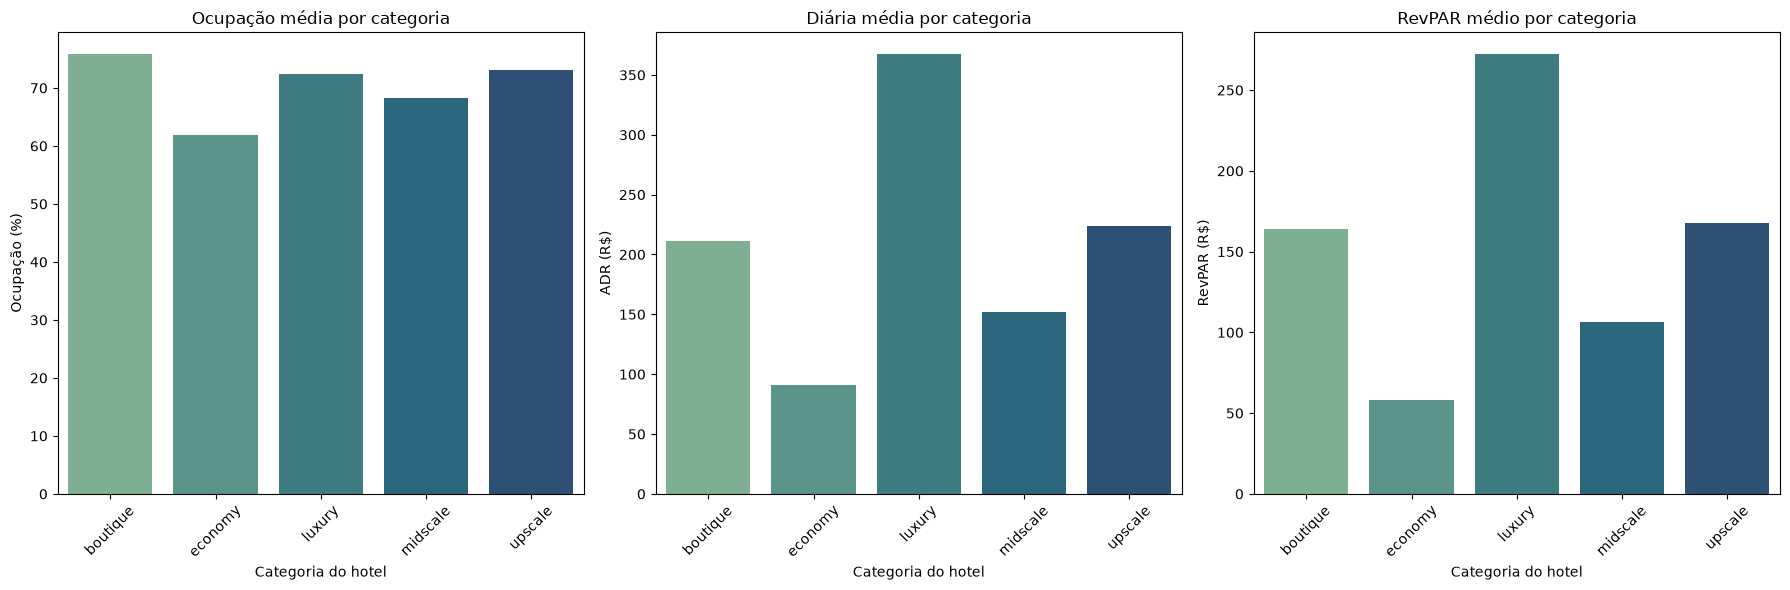

In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 6))

indicadores = [
    ("ocupacao_media", "Ocupação média por categoria", "Ocupação (%)"),
    ("adr_medio", "Diária média por categoria", "ADR (R$)"),
    ("revpar_medio", "RevPAR médio por categoria", "RevPAR (R$)")
]

for eixo, (coluna, titulo, rotulo) in zip(eixos, indicadores):

    sns.barplot(
        data=resumo_tiers,
        x="tier",
        y=coluna,
        hue="tier",
        palette="crest",
        legend=False,
        ax=eixo
    )

    eixo.set_title(titulo)
    eixo.set_xlabel("Categoria do hotel")
    eixo.set_ylabel(rotulo)
    eixo.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 1. Comparação entre categorias

**Objetivo:** Comparar a ocupação, a diária média (ADR) e a receita por quarto disponível (RevPAR) entre as categorias de hotéis.

**Interpretação:** Os hotéis boutique apresentam a maior ocupação média (75,8%). Os hotéis de luxo possuem o maior ADR (R$ 367,23) e RevPAR (R$ 272,16). A categoria econômica apresenta os menores resultados nos três indicadores.

**Conclusão:** Os hotéis de luxo se destacam em receita por quarto, enquanto os boutique apresentam maior ocupação média.


In [5]:
daily_market["date"] = pd.to_datetime(daily_market["date"])

evolucao = (
    daily_market
    .groupby("date")
    .agg(
        ocupacao=("occupancy", "mean"),
        adr=("adr", "mean")
    )
    .reset_index()
)

eventos = (
    daily_market[daily_market["demand_event"].notna() &
                 (daily_market["demand_event"].str.strip() != "")]
    [["date", "demand_event"]]
    .drop_duplicates()
)

print("Período:", evolucao["date"].min(), "até", evolucao["date"].max())
print("Quantidade de datas:", len(evolucao))
print("Eventos identificados:", eventos["demand_event"].nunique())

Período: 2027-01-04 00:00:00 até 2028-12-31 00:00:00
Quantidade de datas: 728
Eventos identificados: 6


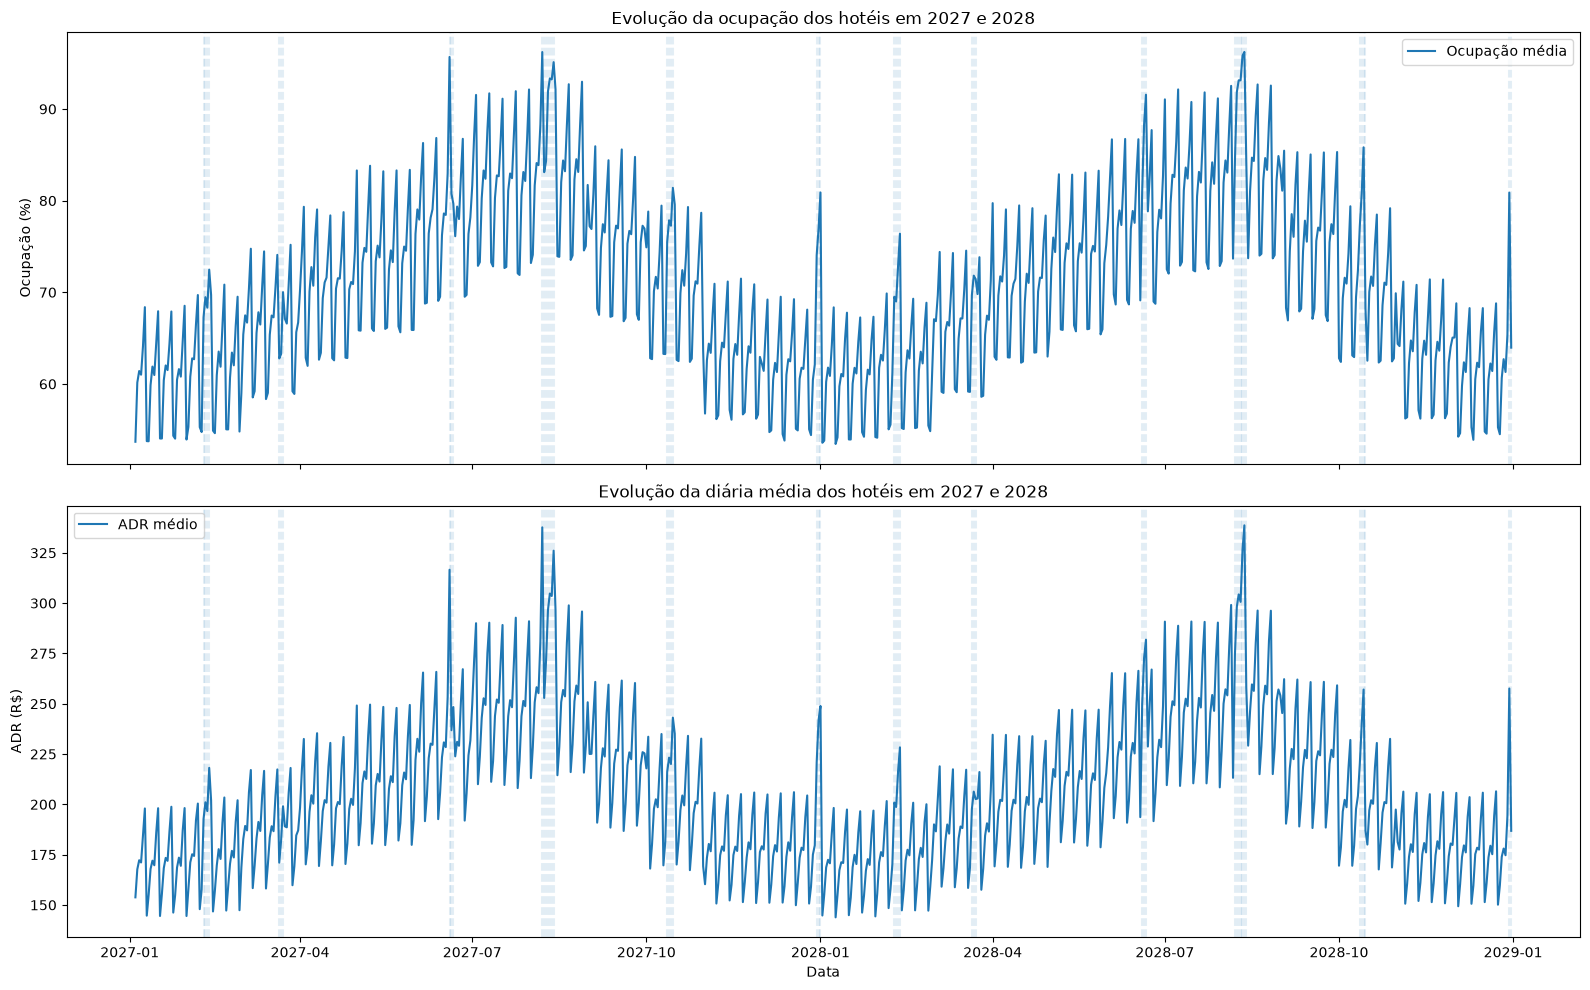

In [6]:
fig, eixos = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Gráfico de ocupação
eixos[0].plot(
    evolucao["date"],
    evolucao["ocupacao"] * 100,
    label="Ocupação média"
)

eixos[0].set_title("Evolução da ocupação dos hotéis em 2027 e 2028")
eixos[0].set_ylabel("Ocupação (%)")
eixos[0].legend()

# Gráfico de diária
eixos[1].plot(
    evolucao["date"],
    evolucao["adr"],
    label="ADR médio"
)

eixos[1].set_title("Evolução da diária média dos hotéis em 2027 e 2028")
eixos[1].set_ylabel("ADR (R$)")
eixos[1].set_xlabel("Data")
eixos[1].legend()

# Marcação dos dias com eventos
for data in eventos["date"].unique():
    for eixo in eixos:
        eixo.axvline(data, alpha=0.12, linestyle="--")

plt.tight_layout()
plt.show()

### 2. Evolução temporal e eventos

**Objetivo:** Analisar a evolução da ocupação e da diária média (ADR) ao longo de 2027 e 2028, observando os períodos com eventos.

**Interpretação:** A ocupação e as diárias variam ao longo do período. Na média mensal, agosto apresenta a maior ocupação (84%) e janeiro a menor (61%). Os períodos com eventos permitem observar possíveis associações com mudanças nos indicadores.

**Conclusão:** A sazonalidade e a ocorrência de eventos estão associadas a diferenças no desempenho; essa relação, por si só, não comprova causalidade.


In [7]:
# Índices de ocupação e preço: média geral = 100
posicionamento = (
    daily_market
    .groupby(["hotel_id", "hotel_name", "tier"])
    .agg(
        ocupacao_media=("occupancy", "mean"),
        adr_medio=("adr", "mean")
    )
    .reset_index()
)

media_ocupacao = posicionamento["ocupacao_media"].mean()
media_adr = posicionamento["adr_medio"].mean()

posicionamento["indice_ocupacao"] = posicionamento["ocupacao_media"] / media_ocupacao * 100
posicionamento["indice_preco"] = posicionamento["adr_medio"] / media_adr * 100

display(posicionamento.round(2))


,hotel_id,hotel_name,tier,ocupacao_media,adr_medio,indice_ocupacao,indice_preco
0,H01,Alder & Quay Hotel,upscale,0.74,227.84,103.98,110.02
1,H02,The Lantern House,boutique,0.76,258.43,106.72,124.79
2,H03,Marisol Bay Resort,luxury,0.73,385.76,102.58,186.27
3,H04,Harborlight Suites,upscale,0.75,245.59,105.57,118.59
4,H05,The Copper Meridian,luxury,0.72,348.70,101.35,168.38
5,H06,Seabright Grand,upscale,0.73,214.78,102.69,103.71
6,H07,The Wren Rooms,boutique,0.77,195.17,108.38,94.24
7,H08,Northgate Inn,economy,0.64,96.17,89.56,46.44
8,H09,Cedar & Salt Hotel,midscale,0.68,144.41,95.34,69.73
9,H10,Kestrel Park Hotel,midscale,0.69,159.80,96.86,77.16


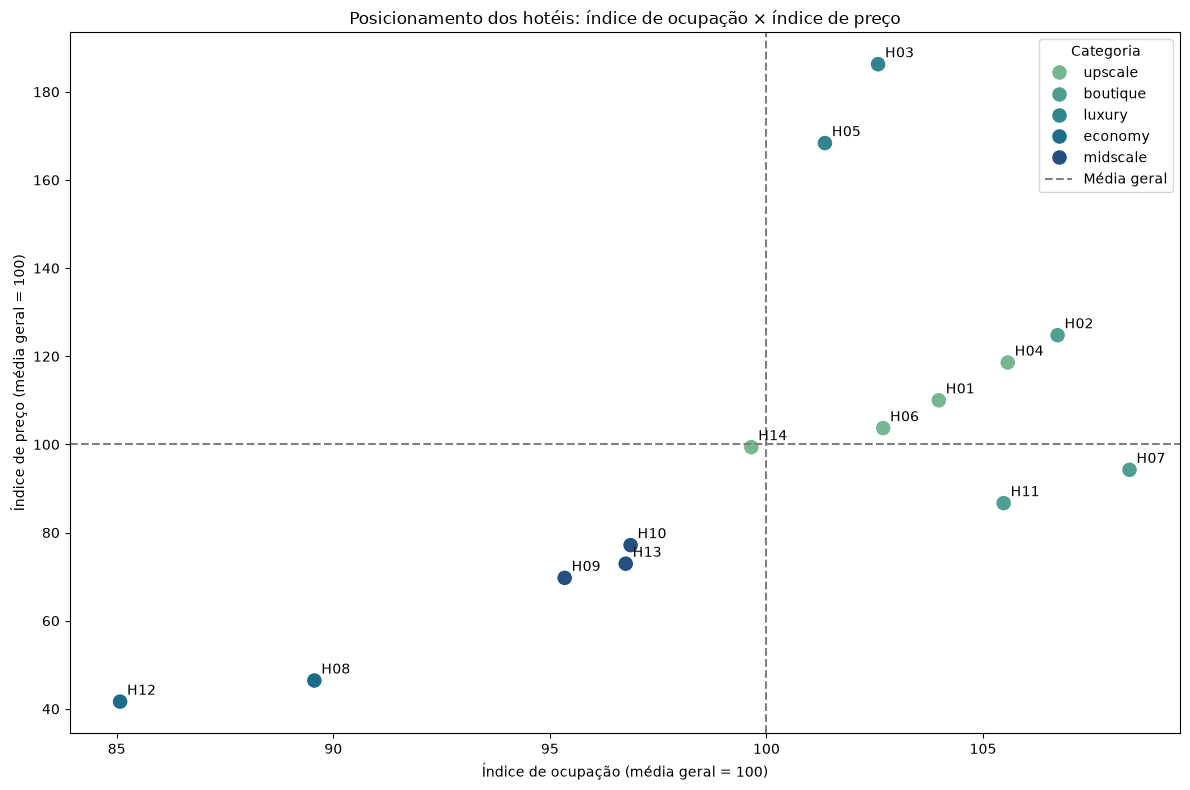

In [8]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=posicionamento,
    x="indice_ocupacao",
    y="indice_preco",
    hue="tier",
    s=130,
    palette="crest"
)

plt.axvline(100, linestyle="--", color="gray", label="Média geral")
plt.axhline(100, linestyle="--", color="gray")

for _, hotel in posicionamento.iterrows():
    plt.annotate(
        hotel["hotel_id"],
        (hotel["indice_ocupacao"], hotel["indice_preco"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Posicionamento dos hotéis: índice de ocupação × índice de preço")
plt.xlabel("Índice de ocupação (média geral = 100)")
plt.ylabel("Índice de preço (média geral = 100)")
plt.legend(title="Categoria")
plt.tight_layout()
plt.show()


### 3. Posicionamento dos hotéis

**Objetivo:** Comparar os hotéis considerando os índices de ocupação e de preço, usando a média geral como referência.

**Interpretação:** O valor 100 representa a média geral. Valores acima de 100 indicam desempenho acima da média no indicador; valores abaixo de 100 indicam desempenho abaixo dela.

**Conclusão:** Os quadrantes ajudam a identificar hotéis com diferentes combinações de posicionamento de preço e ocupação.


In [9]:
desvio_mars = daily_market.copy()

desvio_mars["desvio_mars_pct"] = (
    (desvio_mars["adr"] - desvio_mars["mars_rate"])
    / desvio_mars["mars_rate"]
) * 100

resumo_mars = (
    desvio_mars
    .groupby("tier")
    .agg(
        desvio_medio=("desvio_mars_pct", "mean"),
        mars_medio=("mars_rate", "mean"),
        adr_medio=("adr", "mean")
    )
    .reset_index()
    .round(2)
)

display(resumo_mars)

,tier,desvio_medio,mars_medio,adr_medio
0,boutique,0.72,210.26,211.05
1,economy,0.22,91.08,91.22
2,luxury,0.11,366.78,367.23
3,midscale,0.03,151.71,151.76
4,upscale,0.93,221.72,223.51


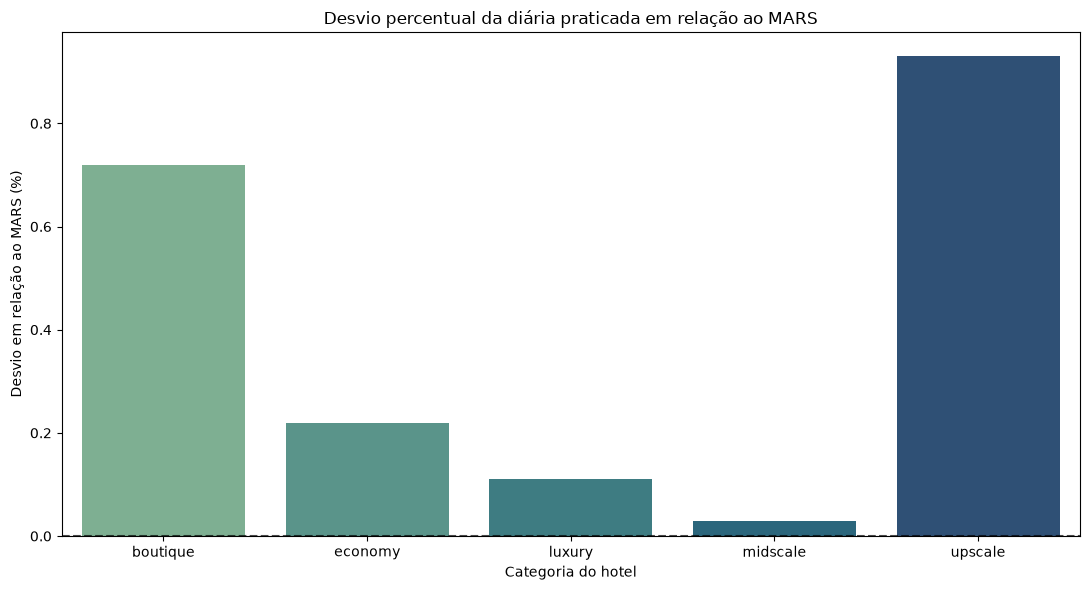

In [10]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=resumo_mars,
    x="tier",
    y="desvio_medio",
    hue="tier",
    palette="crest",
    legend=False
)

plt.axhline(0, color="black", linestyle="--", alpha=0.7)

plt.title("Desvio percentual da diária praticada em relação ao MARS")
plt.xlabel("Categoria do hotel")
plt.ylabel("Desvio em relação ao MARS (%)")
plt.tight_layout()
plt.show()


### 4. Desvio em relação ao MARS

**Objetivo:** Comparar as diárias praticadas pelos hotéis com a tarifa de referência MARS.

**Interpretação:** O desvio percentual mostra quanto o ADR está acima ou abaixo da referência MARS. Valores positivos indicam diária acima da referência; valores negativos indicam diária abaixo dela.

**Conclusão:** A comparação permite observar diferenças nas estratégias de precificação entre as categorias.


In [11]:
avaliacoes_cenarios = (
    reviews
    .merge(
        review_scenarios[["scenario_id", "label"]],
        on="scenario_id",
        how="left"
    )
)

resumo_cenarios = (
    avaliacoes_cenarios
    .groupby("label")
    .agg(
        quantidade=("review_id", "count"),
        avaliacao_media=("rating", "mean")
    )
    .reset_index()
    .sort_values("avaliacao_media", ascending=True)
)

resumo_cenarios["avaliacao_media"] = (
    resumo_cenarios["avaliacao_media"].round(2)
)

display(resumo_cenarios)

,label,quantidade,avaliacao_media
0,Billing and charges,1027,1.63
3,Cleanliness,868,1.69
6,Noise and sleep,1250,2.42
7,Room condition,1401,2.48
10,Wifi and connectivity,765,2.74
2,Check-in and queue,1006,2.81
1,Breakfast and food,1023,3.73
4,Group or family stay,472,4.00
8,Service recovery,1206,4.33
5,Location and access,1219,4.58


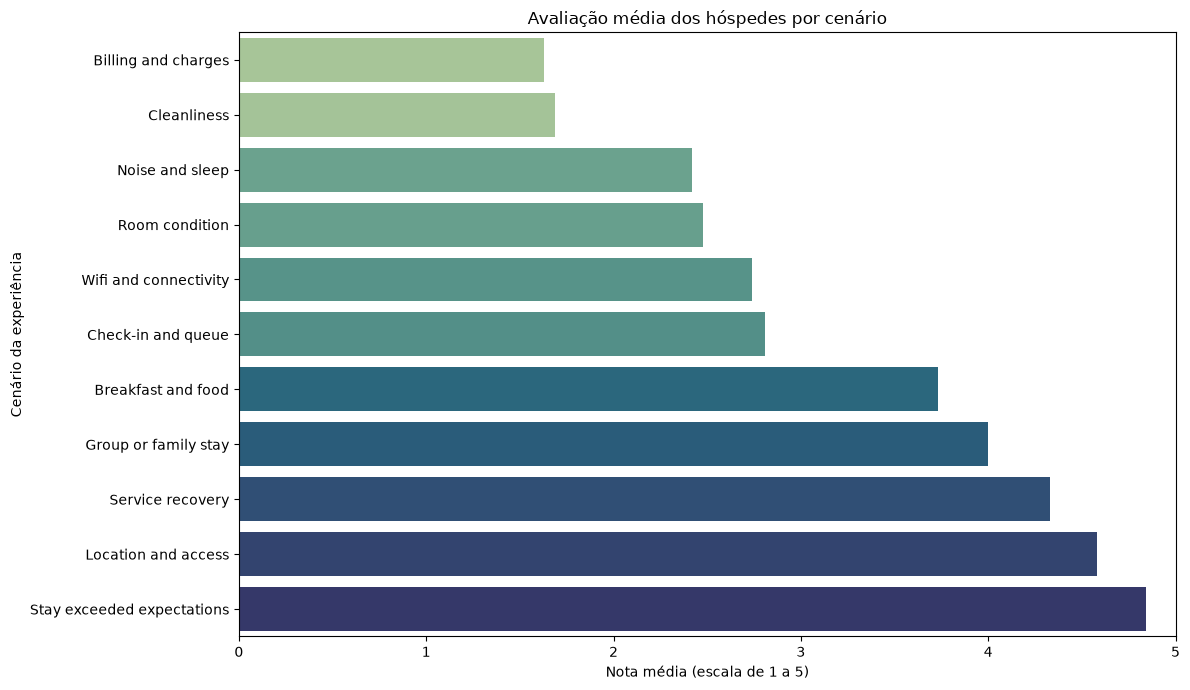

In [12]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=resumo_cenarios,
    x="avaliacao_media",
    y="label",
    hue="avaliacao_media",
    palette="crest",
    legend=False
)

plt.title("Avaliação média dos hóspedes por cenário")
plt.xlabel("Nota média (escala de 1 a 5)")
plt.ylabel("Cenário da experiência")
plt.xlim(0, 5)

plt.tight_layout()
plt.show()

### 5. Cenários das avaliações

**Objetivo:** Identificar quais situações estão relacionadas às avaliações dos hóspedes.

**Interpretação:** Localização e recuperação de serviço apresentam as maiores médias de avaliação. Limpeza e cobrança apresentam as menores médias.

**Conclusão:** Os resultados apontam oportunidades de melhoria principalmente nos processos de limpeza e cobrança.


In [13]:
fluxo_sankey = (
    reviews
    .merge(
        review_scenarios[["scenario_id", "label"]],
        on="scenario_id",
        how="left"
    )
    .groupby(["label", "sentiment"])
    .size()
    .reset_index(name="quantidade")
)

display(fluxo_sankey.head(15))

,label,sentiment,quantidade
0,Billing and charges,negative,1018
1,Billing and charges,neutral,9
2,Breakfast and food,negative,22
3,Breakfast and food,neutral,375
4,Breakfast and food,positive,626
5,Check-in and queue,negative,766
6,Check-in and queue,neutral,138
7,Check-in and queue,positive,102
8,Cleanliness,negative,744
9,Cleanliness,neutral,84


In [14]:
import plotly.graph_objects as go

cenarios = fluxo_sankey["label"].unique().tolist()
sentimentos = fluxo_sankey["sentiment"].dropna().unique().tolist()

rotulos = cenarios + sentimentos
indice = {nome: i for i, nome in enumerate(rotulos)}

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=rotulos,
        pad=18,
        thickness=20
    ),
    link=dict(
        source=[indice[x] for x in fluxo_sankey["label"]],
        target=[indice[x] for x in fluxo_sankey["sentiment"]],
        value=fluxo_sankey["quantidade"]
    )
)])

fig.update_layout(
    title_text="Fluxo entre cenários de avaliação e sentimentos dos hóspedes",
    font_size=11
)

fig.show()

### 6. Diagrama Sankey

**Objetivo:** Representar a relação entre os cenários das avaliações e os sentimentos dos hóspedes.

**Interpretação:** A largura dos fluxos representa a quantidade de avaliações que conecta cada cenário ao sentimento correspondente.

**Conclusão:** O diagrama facilita a visualização dos sentimentos associados aos diferentes cenários de experiência.


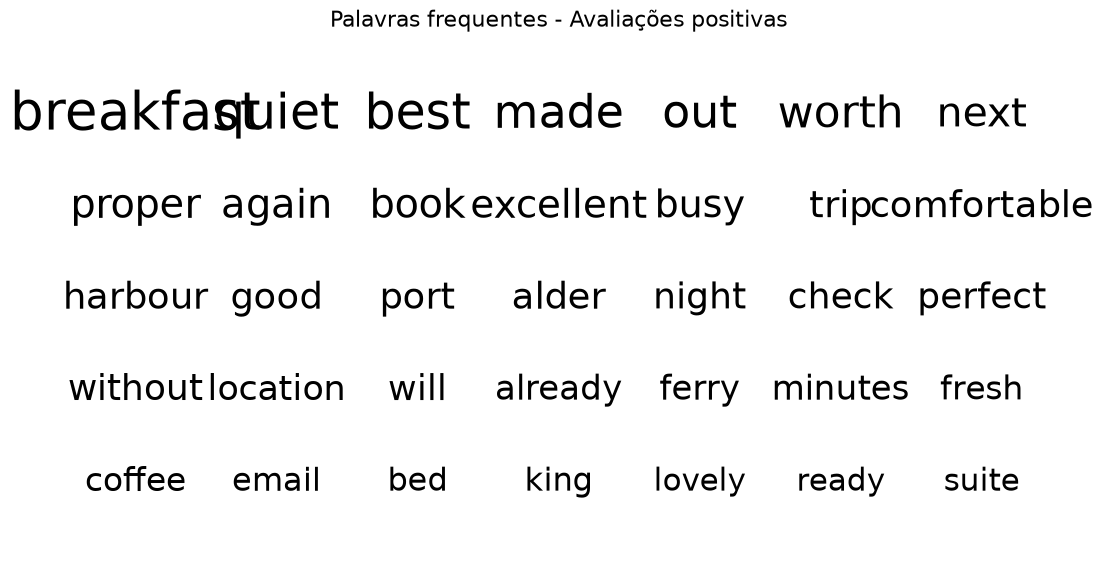

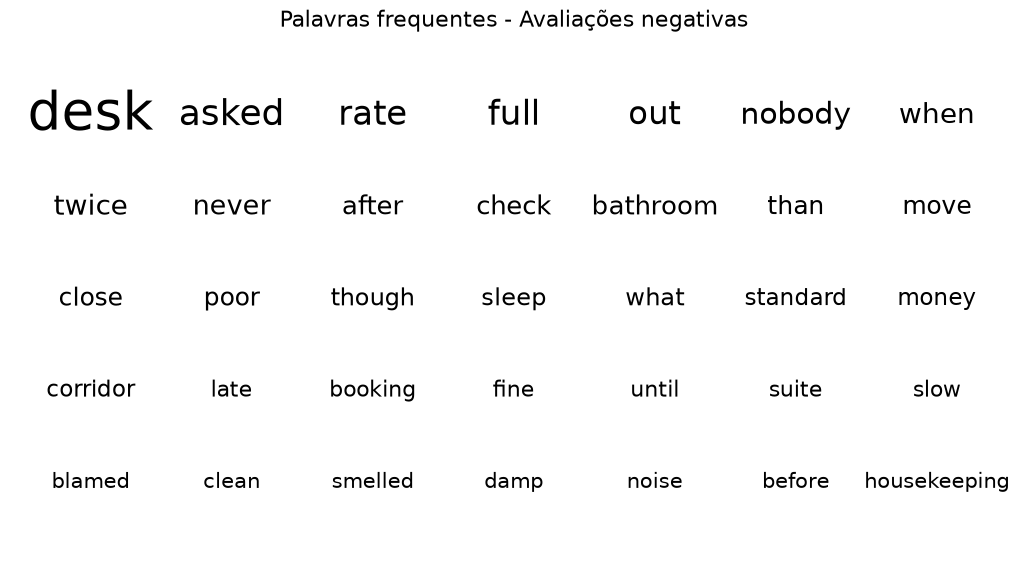

In [15]:
from collections import Counter
import re
import matplotlib.pyplot as plt
import numpy as np

# Palavras comuns em inglês que não ajudam na análise
stopwords = {
    "the", "and", "was", "were", "is", "are", "a", "an",
    "to", "of", "in", "for", "on", "with", "it", "this",
    "that", "my", "we", "our", "i", "they", "at", "but",
    "not", "have", "had", "very", "be", "as", "from",
    "hotel", "room", "stay", "stayed", "would", "could",
    "there", "their", "you", "your", "so", "if", "or",
    "me", "one", "all", "no", "wasn't", "did", "do"
}

def criar_nuvem(textos, titulo):
    palavras = re.findall(r"\b[a-zA-Z]{3,}\b", textos.lower())

    frequencias = Counter(
        palavra for palavra in palavras
        if palavra not in stopwords
    )

    principais = frequencias.most_common(35)

    if not principais:
        print("Não foram encontradas palavras suficientes.")
        return

    palavras_top = [item[0] for item in principais]
    valores = np.array([item[1] for item in principais])

    tamanhos = 10 + (valores / valores.max()) * 28

    fig, ax = plt.subplots(figsize=(13, 7))

    for i, (palavra, tamanho) in enumerate(zip(palavras_top, tamanhos)):
        coluna = i % 7
        linha = i // 7

        x = 0.08 + coluna * 0.14
        y = 0.85 - linha * 0.17

        ax.text(
            x, y, palavra,
            fontsize=tamanho,
            ha="center",
            va="center",
            transform=ax.transAxes
        )

    ax.set_title(titulo, fontsize=16)
    ax.axis("off")
    plt.show()


# Separar avaliações positivas e negativas
textos_positivos = " ".join(
    reviews.loc[reviews["sentiment"] == "positive", "text"]
    .dropna()
    .astype(str)
)

textos_negativos = " ".join(
    reviews.loc[reviews["sentiment"] == "negative", "text"]
    .dropna()
    .astype(str)
)

# Gerar as duas nuvens
criar_nuvem(textos_positivos, "Palavras frequentes - Avaliações positivas")
criar_nuvem(textos_negativos, "Palavras frequentes - Avaliações negativas")


### 7. Frequência de palavras nas avaliações

**Objetivo:** Identificar os termos mais frequentes nas avaliações positivas e negativas.

**Interpretação:** Nas avaliações positivas aparecem termos como *breakfast*, *excellent* e *comfortable*. Nas negativas aparecem termos como *desk*, *rate* e *bathroom*.

**Conclusão:** A frequência das palavras ajuda a identificar assuntos recorrentes nas experiências dos hóspedes. Esta visualização é uma alternativa de frequência de palavras, não uma nuvem tradicional gerada pela biblioteca WordCloud.


In [16]:
# Agrupar indicadores por hotel
dados_plotly = (
    daily_market
    .groupby(["hotel_id", "hotel_name", "tier"])
    .agg(
        ocupacao=("occupancy", "mean"),
        adr=("adr", "mean"),
        revpar=("revpar", "mean")
    )
    .reset_index()
)

# Converter ocupação para porcentagem
dados_plotly["ocupacao_pct"] = dados_plotly["ocupacao"] * 100

# Criar gráfico interativo
fig = px.scatter(
    dados_plotly,
    x="ocupacao_pct",
    y="adr",
    color="tier",
    size="revpar",
    hover_name="hotel_name",
    hover_data={
        "hotel_id": True,
        "ocupacao_pct": ":.2f",
        "adr": ":.2f",
        "revpar": ":.2f"
    },
    title="Comparação interativa entre ocupação e ADR dos hotéis",
    labels={
        "ocupacao_pct": "Ocupação média (%)",
        "adr": "Diária média (R$)",
        "tier": "Categoria",
        "revpar": "RevPAR"
    }
)

fig.show()

### 8. Gráfico interativo

**Objetivo:** Permitir a exploração individual dos hotéis por meio de uma visualização interativa.

**Interpretação:** O gráfico relaciona ocupação média, ADR e RevPAR. Ao passar o cursor sobre cada ponto, é possível consultar informações detalhadas do hotel.

**Conclusão:** A interatividade facilita a comparação entre hotéis e a identificação de diferentes padrões de desempenho.


# Etapa 5 — Desenvolvimento do Dashboard

## Público-alvo

O painel será destinado à diretoria da associação hoteleira de Port Alder e aos gerentes dos 14 hotéis da cidade. Seu objetivo é apresentar informações de desempenho de forma clara, permitindo acompanhar indicadores, comparar hotéis e identificar oportunidades de melhoria.

## Decisões apoiadas pelo painel

1. **Desempenho hoteleiro:** identificar quais hotéis e categorias apresentam melhores resultados de ocupação, diária média (ADR) e receita por quarto disponível (RevPAR).

2. **Estratégias de preços:** acompanhar a relação entre ocupação e diária média, identificando diferenças de desempenho entre as categorias hoteleiras.

3. **Experiência dos hóspedes:** identificar os principais pontos positivos e problemas relatados nas avaliações, auxiliando na definição de melhorias nos serviços.

## Estrutura planejada

O dashboard terá:
- Cabeçalho com título e identificação do projeto.
- Quatro indicadores principais (KPIs).
- Gráficos de desempenho, comparação e avaliações.
- Filtros por categoria e período.
- Tabela comparativa dos hotéis.
- Rodapé com a fonte dos dados e aviso de que o dataset é sintético.

In [17]:
print("Hotéis:", len(hotels))
print("Registros diários:", len(daily_market))
print("Avaliações:", len(reviews))

print("\nPeríodo dos dados:")
print(daily_market["date"].min(), "até", daily_market["date"].max())

Hotéis: 14
Registros diários: 10192
Avaliações: 12077

Período dos dados:
2027-01-04 00:00:00 até 2028-12-31 00:00:00


In [18]:
import json
from pathlib import Path

# Localizar a pasta do projeto
PASTA_PROJETO = Path.cwd()

if PASTA_PROJETO.name == "notebooks":
    PASTA_PROJETO = PASTA_PROJETO.parent

PASTA_DASHBOARD = PASTA_PROJETO / "dashboard"
PASTA_DASHBOARD.mkdir(exist_ok=True)

# Selecionar somente as colunas necessárias
dados_diarios = daily_market[
    [
        "hotel_id",
        "hotel_name",
        "tier",
        "date",
        "occupancy",
        "adr",
        "revpar",
        "room_revenue"
    ]
].copy()

dados_avaliacoes = reviews[
    [
        "review_id",
        "hotel_id",
        "review_date",
        "rating",
        "sentiment",
        "scenario_id"
    ]
].copy()

# Converter datas para texto
dados_diarios["date"] = dados_diarios["date"].dt.strftime("%Y-%m-%d")
dados_avaliacoes["review_date"] = pd.to_datetime(
    dados_avaliacoes["review_date"]
).dt.strftime("%Y-%m-%d")

# Organizar os dados em um único arquivo
dados_dashboard = {
    "hotels": hotels[
        ["hotel_id", "name", "tier", "rooms"]
    ].to_dict(orient="records"),

    "daily_market": dados_diarios.to_dict(orient="records"),

    "reviews": dados_avaliacoes.to_dict(orient="records"),

    "review_scenarios": review_scenarios[
        ["scenario_id", "label"]
    ].to_dict(orient="records")
}

# Salvar arquivo JSON
caminho_json = PASTA_DASHBOARD / "dados_dashboard.json"

with open(caminho_json, "w", encoding="utf-8") as arquivo:
    json.dump(
        dados_dashboard,
        arquivo,
        ensure_ascii=False,
        indent=2
    )

print("Arquivo criado com sucesso!")
print("Local:", caminho_json)
print("Registros diários:", len(dados_dashboard["daily_market"]))
print("Avaliações:", len(dados_dashboard["reviews"]))
print("Hotéis:", len(dados_dashboard["hotels"]))

Arquivo criado com sucesso!
Local: c:\Users\luiza\Documents\Projetos\projeto-integrador-ciencia-de-dados\dashboard\dados_dashboard.json
Registros diários: 10192
Avaliações: 12077
Hotéis: 14
